开始训练，请稍候...
训练完成！开始生成可视化数据...


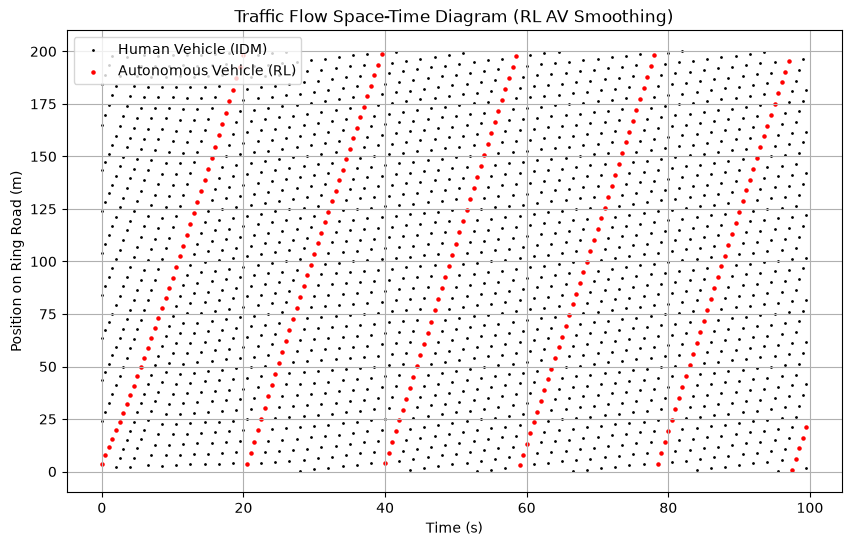

In [11]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

class RingRoadEnv(gym.Env):
    """
    单车道环形路模拟环境
    包含 N 辆车，其中索引为 0 的是自动驾驶车辆 (AV)，受 RL Agent 控制。
    其余车辆是人类驾驶车辆 (HV)，由 IDM 模型控制。
    """
    def __init__(self, num_vehicles=10, ring_length=200):
        super(RingRoadEnv, self).__init__()
        self.num_vehicles = num_vehicles
        self.ring_length = ring_length
        self.dt = 0.5  # 仿真步长(秒)
        
        # IDM 参数
        self.v0 = 15.0      # 目标速度 (m/s)
        self.T = 1.5        # 安全时距 (s)
        self.a = 1.0        # 最大加速度
        self.b = 1.5        # 舒适减速度
        self.s0 = 2.0       # 最小安全距离

        # 动作空间：AV 的加速度，范围 [-3, 3] m/s^2
        self.action_space = spaces.Box(low=-3.0, high=3.0, shape=(1,), dtype=np.float32)
        
        # 状态空间：[与前车的间距, 与前车的速度差, 自己的当前速度]
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(3,), dtype=np.float32)

    def reset(self, seed=None):
        # 初始化车辆位置（均匀分布）和速度（加入一点随机扰动引发堵车）
        self.positions = np.linspace(0, self.ring_length, self.num_vehicles, endpoint=False)
        self.velocities = np.ones(self.num_vehicles) * (self.v0 / 2) + np.random.normal(0, 1, self.num_vehicles)
        self.step_count = 0
        return self._get_obs(), {}

    def _get_obs(self):
        # 获取 AV (车 0) 的状态
        headway, dv = self._get_headway_and_dv(0)
        return np.array([headway, dv, self.velocities[0]], dtype=np.float32)

    def _get_headway_and_dv(self, i):
        # 环形路上的前车是 i+1 (如果是最后一辆，前车是 0)
        leader_idx = (i + 1) % self.num_vehicles
        headway = (self.positions[leader_idx] - self.positions[i]) % self.ring_length
        dv = self.velocities[i] - self.velocities[leader_idx]
        return headway, dv

    def step(self, action):
        accelerations = np.zeros(self.num_vehicles)
        
        # ==========================================
        # 修改点 1：为 AV (RL Agent) 引入动态安全护盾 (AEB)
        # ==========================================
        s_av, dv_av = self._get_headway_and_dv(0)
        # 定义动态危险阈值：最小绝对距离(2米) + 0.8秒的反应缓冲距离
        critical_distance = 2.0 + self.velocities[0] * 0.8 
        
        aeb_penalty = 0.0
        if s_av < critical_distance:
            # 强制接管：无视 RL 的输出，直接踩死刹车
            accelerations[0] = -4.0 
            # 给予严厉惩罚，防止 RL Agent "偷懒" 依赖 AEB 帮它刹车
            aeb_penalty = -10.0 
        else:
            accelerations[0] = action[0]

        # ==========================================
        # 修改点 2：为 HV (人类车辆) 添加防穿模硬约束
        # ==========================================
        for i in range(1, self.num_vehicles):
            s, dv = self._get_headway_and_dv(i)
            v = self.velocities[i]
            
            s_star = self.s0 + v * self.T + (v * dv) / (2 * np.sqrt(self.a * self.b))
            s_star = max(s_star, self.s0)
            
            # 正常 IDM 计算
            acc_idm = self.a * (1 - (v / self.v0)**4 - (s_star / max(s, 0.1))**2)
            
            # 因为 dt=0.5 较大，IDM 偶尔会积分过头。加入硬性刹车兜底：
            if s < self.s0:
                accelerations[i] = -4.0
            else:
                accelerations[i] = np.clip(acc_idm, -4.0, 2.0)

        # 3. 更新速度和位置 (欧拉积分)
        self.velocities += accelerations * self.dt
        # 限制速度不能为负（不能倒车），也不能超过最大限速
        self.velocities = np.clip(self.velocities, 0, self.v0) 
        self.positions = (self.positions + self.velocities * self.dt) % self.ring_length
        
        self.step_count += 1
        
        # ==========================================
        # 修改点 3：将惩罚项计入总 Reward
        # ==========================================
        # 基础奖励是全局车流的平均速度，加上触发 AEB 时的严重惩罚
        reward = np.mean(self.velocities) + aeb_penalty
        
        # 如果全局发生极低速拥堵，再给一个轻微惩罚
        if min(self.velocities) < 0.1: 
            reward -= 2.0
            
        done = self.step_count >= 200 # 截断步数
        
        return self._get_obs(), reward, False, done, {}

# 1. 初始化环境与训练模型
env = RingRoadEnv()
print("开始训练，请稍候...")
# 使用 PPO 算法，训练 10000 步 (大约需要 5-10 秒)
model = PPO("MlpPolicy", env, verbose=0)
model.learn(total_timesteps=10000)
print("训练完成！开始生成可视化数据...")

# 2. 测试训练好的模型，并记录轨迹用于可视化
obs, _ = env.reset()
history_positions = []
history_times = []

for t in range(200):
    action, _states = model.predict(obs, deterministic=True)
    obs, rewards, dones, truncated, info = env.step(action)
    
    # 记录时间步和每辆车的位置
    history_positions.append(env.positions.copy())
    history_times.append(np.ones(env.num_vehicles) * t * env.dt)

# 3. 画出时空图 (Space-Time Diagram)
history_positions = np.array(history_positions)
history_times = np.array(history_times)

plt.figure(figsize=(10, 6))
# 画人类驾驶车辆 (黑线)
for i in range(1, env.num_vehicles):
    # 处理环形路 0-200 的穿越跳变，画图更好看
    pos = history_positions[:, i]
    time = history_times[:, i]
    plt.scatter(time, pos, c='black', s=1, label="Human Vehicle (IDM)" if i==1 else "")

# 画自动驾驶车辆 (红线)
plt.scatter(history_times[:, 0], history_positions[:, 0], c='red', s=5, label="Autonomous Vehicle (RL)")

plt.title("Traffic Flow Space-Time Diagram (RL AV Smoothing)")
plt.xlabel("Time (s)")
plt.ylabel("Position on Ring Road (m)")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

# 创建画布
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.axis('off') 
ax.set_title("Ring Road Simulation\n(Red: RL Autonomous, Black: Human IDM)")

# 画出环形路轨道
circle = plt.Circle((0, 0), 1.0, color='gray', fill=False, linewidth=12, alpha=0.3)
ax.add_artist(circle)

# 初始化散点
scat = ax.scatter([], [], s=80, zorder=3)
colors = ['red'] + ['black'] * (env.num_vehicles - 1)

def init():
    scat.set_offsets(np.empty((0, 2)))
    return scat,

def update(frame):
    positions = history_positions[frame]
    angles = -(positions / env.ring_length) * 2 * np.pi + np.pi / 2
    x = np.cos(angles)
    y = np.sin(angles)
    
    data = np.c_[x, y]
    scat.set_offsets(data)
    scat.set_color(colors)
    return scat,

ani = animation.FuncAnimation(
    fig, update, frames=len(history_positions),
    init_func=init, interval=500, blit=True
)

# 【关键修改】阻止 matplotlib 画出静态的空图
plt.close(fig) 

# 【关键修改】将动画渲染为带播放控制条的 HTML 交互组件
display(HTML(ani.to_jshtml()))

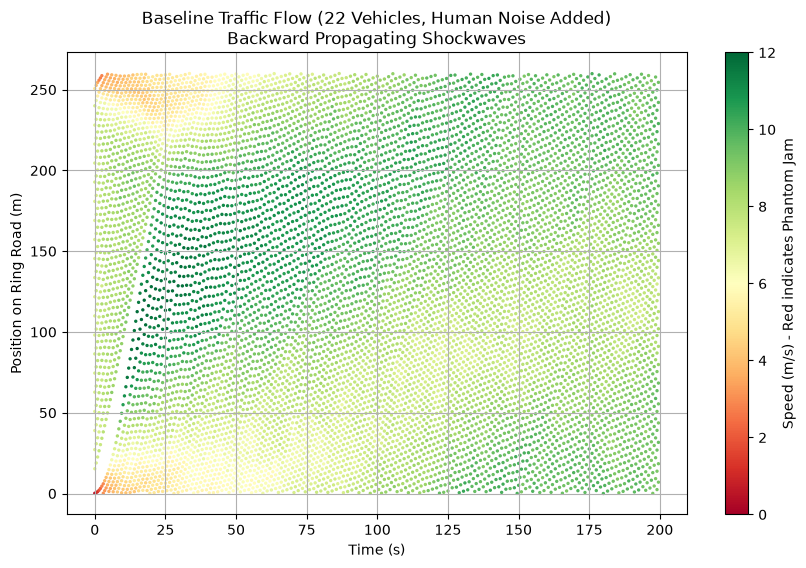

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 提高车辆密度：复刻经典的 22 辆车环形道路实验
num_vehicles = 22
ring_length = 260  
dt = 0.5
steps = 400 # 增加仿真步数，让波的传播更清晰

# IDM 基础参数
v0, T, a, b, s0 = 15.0, 1.0, 1.0, 1.5, 2.0

positions = np.linspace(0, ring_length, num_vehicles, endpoint=False)
# 初始让所有车以 7 m/s 左右的中等速度行驶
velocities = np.ones(num_vehicles) * 7.0 

# 剧烈扰动：第一辆车突然急刹车到静止
velocities[0] = 0.0 

history_positions = []
history_times = []
history_velocities = []

for t in range(steps):
    accelerations = np.zeros(num_vehicles)
    
    for i in range(num_vehicles):
        leader_idx = (i + 1) % num_vehicles
        s = (positions[leader_idx] - positions[i]) % ring_length
        dv = velocities[i] - velocities[leader_idx]
        v = velocities[i]
        
        s_star = s0 + v * T + (v * dv) / (2 * np.sqrt(a * b))
        s_star = max(s_star, s0)
        
        # 纯 IDM 加速度
        acc = a * (1 - (v / v0)**4 - (s_star / max(s, 0.1))**2)
        
        # 【核心修改】：引入人类司机的“随机性/不完美” (Human Noise)
        # 这点微小的噪声是打破物理方程绝对平衡、维持幽灵堵车的关键
        acc += np.random.normal(0, 0.3) 
        
        # 物理硬约束兜底防穿模
        if s < 2.0:
            acc = -4.0
        else:
            acc = np.clip(acc, -4.0, 2.0)
            
        accelerations[i] = acc
        
    velocities += accelerations * dt
    velocities = np.clip(velocities, 0, v0)
    positions = (positions + velocities * dt) % ring_length
    
    history_positions.append(positions.copy())
    history_times.append(np.ones(num_vehicles) * t * dt)
    history_velocities.append(velocities.copy())

history_positions = np.array(history_positions)
history_times = np.array(history_times)
history_velocities = np.array(history_velocities)

# 2. 画图：用颜色映射速度，直观展示堵车波谷
plt.figure(figsize=(10, 6))
for i in range(num_vehicles):
    # cmap='RdYlGn'：红色代表低速(堵车)，绿色代表高速(顺畅)
    plt.scatter(history_times[:, i], history_positions[:, i], 
                c=history_velocities[:, i], cmap='RdYlGn', s=2, vmin=0, vmax=12)

cbar = plt.colorbar()
cbar.set_label("Speed (m/s) - Red indicates Phantom Jam")
plt.title("Baseline Traffic Flow (22 Vehicles, Human Noise Added)\nBackward Propagating Shockwaves")
plt.xlabel("Time (s)")
plt.ylabel("Position on Ring Road (m)")
plt.grid(True)
plt.show()

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

# 创建画布
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.axis('off') 
ax.set_title("Ring Road Simulation\n(Red: RL Autonomous, Black: Human IDM)")

# 画出环形路轨道
circle = plt.Circle((0, 0), 1.0, color='gray', fill=False, linewidth=12, alpha=0.3)
ax.add_artist(circle)

# 初始化散点
scat = ax.scatter([], [], s=80, zorder=3)
colors =['black'] * env.num_vehicles

def init():
    scat.set_offsets(np.empty((0, 2)))
    return scat,

def update(frame):
    positions = history_positions[frame]
    angles = -(positions / ring_length) * 2 * np.pi + np.pi / 2
    x = np.cos(angles)
    y = np.sin(angles)
    
    data = np.c_[x, y]
    scat.set_offsets(data)
    scat.set_color(colors)
    return scat,

ani = animation.FuncAnimation(
    fig, update, frames=len(history_positions),
    init_func=init, interval=500, blit=True
)

# 【关键修改】阻止 matplotlib 画出静态的空图
plt.close(fig) 

# 【关键修改】将动画渲染为带播放控制条的 HTML 交互组件
display(HTML(ani.to_jshtml()))